# Phase 4c — Coherence Rigor with MuQ Audio Probes

Phase 4b showed that coherence "paradoxes" are disagreements between two content probes, and that in ~80% of robust
paradoxes the **audio (CLAP) probe** was the wrong one (CLAP probe R²: arousal 0.20, valence 0.08). Phase 5e found that
MuQ is a far better emotion representation (probe R² 0.51 / 0.41, retrieval on par with lyrics). This notebook re-runs
the **identical Phase 4b protocol** with the audio probe on MuQ instead of CLAP, and compares the two.

* **Audio:** `MuQ-large-msd-iter` layer 7 (`outputs/encoders/audio_muq.npy`). Layer chosen in Phase 5e by **validation**
  ridge R² on the 70/15/15 shared split (`encoder_probe_layers.csv`), not on test.
* **Lyrics:** SBERT `all-mpnet-base-v2` as in Phase 4b, so only the audio side changes.
* Same cross-fitting (5 folds), 200 bootstrap probes per fold, ridge grid, cosine/Euclidean definitions and tests.

Outputs carry a `_muq` suffix; Phase 4b's CLAP outputs are not modified. `genres` is read only in section 7 (evaluation).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, mannwhitneyu
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
SEED    = 42
N_BOOT  = 200
N_FOLDS = 5
RIDGE_ALPHAS = np.logspace(-2, 5, 15)          # Phase 4 grid stopped at 1000 and chose 1000 (its upper edge)
CENTER  = np.array([0.5, 0.5])
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
QCOL    = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))

sids = lyrics_df['song_id'].tolist()                                    # 2,075 multimodal tracks
ENC_DIR   = os.path.join(OUT_DIR, 'encoders')
MUQ_LAYER = 7                                                            # Phase 5e validation choice for AV ridge
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
arow  = {s: i for i, s in enumerate(a_ids)}
X_a  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'), mmap_mode='r')[[arow[s] for s in sids], MUQ_LAYER].astype(np.float64)
X_l  = np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float64)
lab  = merged.set_index('song_id').loc[sids]
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
quad = lab['quadrant'].values
print(f'{len(sids)} tracks  MuQ L{MUQ_LAYER} {X_a.shape}  SBERT {X_l.shape}')

2075 tracks  MuQ L7 (2075, 1024)  SBERT (2075, 768)


## 0. Ground truth check: does MERGE label any audio–lyrics paradoxes?
MERGE ships separate AV annotations for the lyrics dataset. If audio and lyric annotations disagreed for some
tracks, those would be labelled paradoxes we could validate against.

In [2]:
stem = lab['lyrics_path'].map(lambda p: os.path.splitext(os.path.basename(p))[0])
lav  = pd.read_csv(os.path.join(ROOT, 'MERGE_Lyrics_Balanced', 'merge_lyrics_balanced_av_values.csv')).set_index('Song')
Y_lyr = np.c_[stem.map(lav['Arousal']).values, stem.map(lav['Valence']).values]
gap = np.linalg.norm(Y - Y_lyr, axis=1)
def to_quad(av):
    return np.where(av[:, 0] >= .5, np.where(av[:, 1] >= .5, 'Q1', 'Q2'), np.where(av[:, 1] >= .5, 'Q4', 'Q3'))
print(f'Audio vs lyric AV annotation: identical for {np.mean(gap < 1e-9):.1%} of tracks, '
      f'mean distance {gap.mean():.4f}, same quadrant for {np.mean(to_quad(Y) == to_quad(Y_lyr)):.1%}')
print('→ The multimodal set contains no annotated audio–lyrics disagreements. Any "paradox" found below is a\n'
      '  disagreement between the two content probes, not between labels. Its credibility rests on probe accuracy\n'
      '  and stability, which is what this notebook measures.')

Audio vs lyric AV annotation: identical for 97.1% of tracks, mean distance 0.0031, same quadrant for 100.0%
→ The multimodal set contains no annotated audio–lyrics disagreements. Any "paradox" found below is a
  disagreement between the two content probes, not between labels. Its credibility rests on probe accuracy
  and stability, which is what this notebook measures.


## 1. Probe accuracy on the shared held-out split
Probes are trained on the shared 70/15/15 **train** split (tracks in the train subset of both the audio and the
lyrics split, from Phase 5b) and scored on the shared **test** split (n = 302). The baseline predicts the training mean.

In [3]:
cat = set(sids)
mm  = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, subset, scheme='tvt_70_15_15'):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
shared = {sub: read_split('audio', sub) & read_split('lyrics', sub) & cat for sub in ['train', 'validate', 'test']}
mask = {sub: np.isin(sids, list(v)) for sub, v in shared.items()}
print({k: int(v.sum()) for k, v in mask.items()})

def make_probe(alpha=None):
    return make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS) if alpha is None else Ridge(alpha=alpha))

tr, te = mask['train'], mask['test']
rows, probes = [], {}
for name, X in [('audio (MuQ)', X_a), ('lyrics (SBERT)', X_l), ('baseline (train mean)', None)]:
    if X is None:
        P = np.tile(Y[tr].mean(0), (te.sum(), 1)); alpha = np.nan
    else:
        p = make_probe().fit(X[tr], Y[tr]); probes[name] = p
        P = p.predict(X[te]); alpha = p[-1].alpha_
    for j, dim in enumerate(['arousal', 'valence']):
        rows.append({'probe': name, 'dimension': dim, 'ridge_alpha': alpha,
                     'R2': r2_score(Y[te, j], P[:, j]), 'MAE': mean_absolute_error(Y[te, j], P[:, j]),
                     'pearson_r': np.corrcoef(Y[te, j], P[:, j])[0, 1] if X is not None else np.nan})
    rows.append({'probe': name, 'dimension': 'quadrant accuracy', 'ridge_alpha': alpha,
                 'R2': np.nan, 'MAE': np.nan, 'pearson_r': np.nan,
                 'quadrant_acc': np.mean(to_quad(P) == quad[te])})
probe_metrics = pd.DataFrame(rows)
print(probe_metrics.round(3).to_string(index=False))
probe_metrics.to_csv(os.path.join(OUT_DIR, 'coherence_probe_metrics_muq.csv'), index=False)

{'train': 1187, 'validate': 305, 'test': 302}


                probe         dimension  ridge_alpha     R2   MAE  pearson_r  quadrant_acc
          audio (MuQ)           arousal     1000.000  0.515 0.063      0.734           NaN
          audio (MuQ)           valence     1000.000  0.411 0.135      0.643           NaN
          audio (MuQ) quadrant accuracy     1000.000    NaN   NaN        NaN         0.709
       lyrics (SBERT)           arousal     3162.278  0.373 0.074      0.612           NaN
       lyrics (SBERT)           valence     3162.278  0.519 0.121      0.724           NaN
       lyrics (SBERT) quadrant accuracy     3162.278    NaN   NaN        NaN         0.679
baseline (train mean)           arousal          NaN -0.009 0.109        NaN           NaN
baseline (train mean)           valence          NaN -0.002 0.208        NaN           NaN
baseline (train mean) quadrant accuracy          NaN    NaN   NaN        NaN         0.248


In [4]:
clap_pm = pd.read_csv(os.path.join(OUT_DIR, 'coherence_probe_metrics.csv'))
print('Phase 4b (CLAP) probe metrics, same split, for comparison:')
print(clap_pm.round(3).to_string(index=False))

Phase 4b (CLAP) probe metrics, same split, for comparison:
                probe         dimension  ridge_alpha     R2   MAE  pearson_r  quadrant_acc
         audio (CLAP)           arousal     1000.000  0.199 0.088      0.450           NaN
         audio (CLAP)           valence     1000.000  0.080 0.191      0.287           NaN
         audio (CLAP) quadrant accuracy     1000.000    NaN   NaN        NaN         0.394
       lyrics (SBERT)           arousal     3162.278  0.373 0.074      0.612           NaN
       lyrics (SBERT)           valence     3162.278  0.519 0.121      0.724           NaN
       lyrics (SBERT) quadrant accuracy     3162.278    NaN   NaN        NaN         0.679
baseline (train mean)           arousal          NaN -0.009 0.109        NaN           NaN
baseline (train mean)           valence          NaN -0.002 0.208        NaN           NaN
baseline (train mean) quadrant accuracy          NaN    NaN   NaN        NaN         0.248


## 2. Cross-fitted coherence with bootstrap uncertainty

5-fold cross-fitting over all 2,075 tracks (stratified by quadrant). In each fold the ridge strength is chosen by
RidgeCV on the fold's training part; the point prediction comes from that probe, and 200 bootstrap resamples of the
training part give 200 alternative probes. Every track therefore gets 1 + 200 out-of-fold AV predictions per modality.

Two coherence definitions are computed from each prediction pair:
* **cosine** (Phase 4): cos(â − c, l̂ − c) with c = (0.5, 0.5); range [−1, 1], paradox when < 0;
* **Euclidean**: −‖â − l̂‖, the (negated) distance between the two predicted AV points; higher = more coherent.

In [5]:
def cos_coh(A, L):
    A, L = A - CENTER, L - CENTER
    return (A * L).sum(-1) / (np.linalg.norm(A, axis=-1) * np.linalg.norm(L, axis=-1) + 1e-12)

def euc_coh(A, L):
    return -np.linalg.norm(A - L, axis=-1)

rng = np.random.default_rng(SEED)
n = len(sids)
pred_a, pred_l = np.zeros((n, 2)), np.zeros((n, 2))
boot_a, boot_l = np.zeros((N_BOOT, n, 2)), np.zeros((N_BOOT, n, 2))
fold_alpha = []
for f, (itr, ite) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_a, quad)):
    pa = make_probe().fit(X_a[itr], Y[itr]); pl = make_probe().fit(X_l[itr], Y[itr])
    aa, al = pa[-1].alpha_, pl[-1].alpha_
    fold_alpha.append((aa, al))
    pred_a[ite], pred_l[ite] = pa.predict(X_a[ite]), pl.predict(X_l[ite])
    for b in range(N_BOOT):
        ib = rng.choice(itr, size=len(itr), replace=True)
        boot_a[b, ite] = make_probe(aa).fit(X_a[ib], Y[ib]).predict(X_a[ite])
        boot_l[b, ite] = make_probe(al).fit(X_l[ib], Y[ib]).predict(X_l[ite])
    print(f'fold {f}: ridge α audio={aa:.0f} lyrics={al:.0f}')

oof_err = pd.DataFrame({
    'probe': ['audio (MuQ)', 'lyrics (SBERT)'],
    'R2_arousal': [r2_score(Y[:, 0], pred_a[:, 0]), r2_score(Y[:, 0], pred_l[:, 0])],
    'R2_valence': [r2_score(Y[:, 1], pred_a[:, 1]), r2_score(Y[:, 1], pred_l[:, 1])],
    'MAE_arousal': [mean_absolute_error(Y[:, 0], pred_a[:, 0]), mean_absolute_error(Y[:, 0], pred_l[:, 0])],
    'MAE_valence': [mean_absolute_error(Y[:, 1], pred_a[:, 1]), mean_absolute_error(Y[:, 1], pred_l[:, 1])],
})
print('\nOut-of-fold probe accuracy (all 2,075 tracks):')
print(oof_err.round(3).to_string(index=False))

coh = pd.DataFrame({'song_id': sids, 'quadrant': quad, 'arousal': Y[:, 0], 'valence': Y[:, 1],
                    'pred_audio_arousal': pred_a[:, 0], 'pred_audio_valence': pred_a[:, 1],
                    'pred_lyrics_arousal': pred_l[:, 0], 'pred_lyrics_valence': pred_l[:, 1]})
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot_a, boot_l)                                            # (N_BOOT, n)
    coh[f'coh_{name}'] = fn(pred_a, pred_l)
    coh[f'coh_{name}_lo'], coh[f'coh_{name}_hi'] = np.percentile(bs, [2.5, 97.5], axis=0)
    coh[f'coh_{name}_ci_width'] = coh[f'coh_{name}_hi'] - coh[f'coh_{name}_lo']

coh['status_cos'] = np.select([coh.coh_cos_hi < 0, coh.coh_cos_lo > 0], ['robust paradox', 'robust coherent'], 'uncertain')
coh['point_paradox_cos'] = coh.coh_cos < 0
print('\nCosine coherence, cross-fitted:')
print(f'  point estimate < 0 (Phase 4 paradox definition): {coh.point_paradox_cos.sum()} tracks ({coh.point_paradox_cos.mean():.1%})')
print(coh['status_cos'].value_counts().to_string())

fold 0: ridge α audio=1000 lyrics=3162


fold 1: ridge α audio=1000 lyrics=3162


fold 2: ridge α audio=1000 lyrics=3162


fold 3: ridge α audio=1000 lyrics=3162


fold 4: ridge α audio=1000 lyrics=3162

Out-of-fold probe accuracy (all 2,075 tracks):
         probe  R2_arousal  R2_valence  MAE_arousal  MAE_valence
   audio (MuQ)       0.563       0.494        0.065        0.131
lyrics (SBERT)       0.334       0.518        0.081        0.127

Cosine coherence, cross-fitted:
  point estimate < 0 (Phase 4 paradox definition): 263 tracks (12.7%)
status_cos
robust coherent    1354
uncertain           655
robust paradox       66


### 2a. MuQ coherence vs CLAP coherence (Phase 4b)
How many of Phase 4b's paradoxes survive a better audio probe? Which tracks stay paradoxical under both?

In [6]:
old = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_v2.parquet')).set_index('song_id')
p4  = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_scores.parquet')).set_index('song_id')['coherence_score']
c2 = coh.set_index('song_id').join(old[['coh_cos', 'status_cos']].add_suffix('_clap')).join(p4.rename('coh_phase4'))
print(f"Spearman(CLAP cosine, MuQ cosine) = {spearmanr(c2.coh_cos_clap, c2.coh_cos)[0]:.3f}")
print(pd.crosstab(c2.status_cos_clap, c2.status_cos, margins=True, rownames=['CLAP (4b)'], colnames=['MuQ (4c)']).to_string())
both = (c2.status_cos_clap == 'robust paradox') & (c2.status_cos == 'robust paradox')
print(f"\nRobust paradoxes: CLAP {int((c2.status_cos_clap == 'robust paradox').sum())}, "
      f"MuQ {int((c2.status_cos == 'robust paradox').sum())}, under both {int(both.sum())}")
gallery = c2.nsmallest(15, 'coh_phase4')
print('\nFigure 12 gallery tracks (Phase 4 lowest coherence) under CLAP and MuQ:')
print(gallery[['quadrant', 'coh_phase4', 'coh_cos_clap', 'status_cos_clap', 'coh_cos', 'coh_cos_lo', 'coh_cos_hi', 'status_cos']]
      .round(3).to_string())
print(f"-> {(gallery.status_cos == 'robust paradox').sum()} of 15 are robust paradoxes under MuQ "
      f"({(gallery.status_cos_clap == 'robust paradox').sum()} under CLAP)")
c2[both].reset_index()[['song_id']].to_csv(os.path.join(OUT_DIR, 'coherence_paradox_both_encoders.csv'), index=False)

Spearman(CLAP cosine, MuQ cosine) = 0.286
MuQ (4c)         robust coherent  robust paradox  uncertain   All
CLAP (4b)                                                        
robust coherent              792               8        176   976
robust paradox                68              15         52   135
uncertain                    494              43        427   964
All                         1354              66        655  2075

Robust paradoxes: CLAP 135, MuQ 66, under both 15

Figure 12 gallery tracks (Phase 4 lowest coherence) under CLAP and MuQ:
             quadrant  coh_phase4  coh_cos_clap status_cos_clap  coh_cos  coh_cos_lo  coh_cos_hi       status_cos
song_id                                                                                                          
MT0009320357       Q2      -1.000        -0.350       uncertain    0.993       0.442       1.000  robust coherent
MT0000231784       Q2      -1.000        -0.901       uncertain    0.998       0.789       1.000

## 3. Is a paradox just probe error?

Because the audio and lyric annotations agree (section 0), a paradox means at least one probe is far from the label.
Here we check (a) which probe is wrong for robust paradoxes, and (b) whether paradoxes are concentrated where the
predictions sit close to the neutral centre, where the cosine direction is ill-defined.

In [7]:
err_a = np.linalg.norm(pred_a - Y, axis=1); err_l = np.linalg.norm(pred_l - Y, axis=1)
coh['err_audio'], coh['err_lyrics'] = err_a, err_l
coh['min_dev_from_center'] = np.minimum(np.linalg.norm(pred_a - CENTER, axis=1), np.linalg.norm(pred_l - CENTER, axis=1))
for st in ['robust paradox', 'uncertain', 'robust coherent']:
    g = coh[coh.status_cos == st]
    print(f'{st:16s} n={len(g):4d}  mean AV error audio={g.err_audio.mean():.3f} lyrics={g.err_lyrics.mean():.3f}  '
          f'audio probe is the worse one: {np.mean(g.err_audio > g.err_lyrics):.0%}  '
          f'median min-deviation from centre={g.min_dev_from_center.median():.3f}')
rho, p = spearmanr(coh.min_dev_from_center, coh.coh_cos_ci_width)
print(f'\nSpearman(min deviation from centre, cosine CI width) = {rho:.3f} (p={p:.1e})')
print(f'Median predicted deviation from centre: audio={np.median(np.linalg.norm(pred_a - CENTER, axis=1)):.3f}  '
      f'lyrics={np.median(np.linalg.norm(pred_l - CENTER, axis=1)):.3f}  labels={np.median(np.linalg.norm(Y - CENTER, axis=1)):.3f}')

robust paradox   n=  66  mean AV error audio=0.204 lyrics=0.270  audio probe is the worse one: 39%  median min-deviation from centre=0.109
uncertain        n= 655  mean AV error audio=0.192 lyrics=0.200  audio probe is the worse one: 47%  median min-deviation from centre=0.074
robust coherent  n=1354  mean AV error audio=0.138 lyrics=0.142  audio probe is the worse one: 47%  median min-deviation from centre=0.148

Spearman(min deviation from centre, cosine CI width) = -0.757 (p=0.0e+00)
Median predicted deviation from centre: audio=0.171  lyrics=0.150  labels=0.253


## 4. Cosine vs Euclidean coherence

Criteria:
* **agreement** between the two scores (Spearman);
* **test–retest reliability**: Spearman correlation between the scores from two independent bootstrap probes,
  averaged over 100 random pairs of bootstrap replicates (higher = the ranking of tracks is less dependent on probe noise);
* **dependence on prediction magnitude**: CI width vs distance of the predictions from the centre.

In [8]:
rel = {}
pairs = rng.choice(N_BOOT, size=(100, 2), replace=True)
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot_a, boot_l)
    rel[name] = np.mean([spearmanr(bs[i], bs[j])[0] for i, j in pairs])
cmp = pd.DataFrame({
    'score': ['cosine', 'Euclidean'],
    'test_retest_spearman': [rel['cos'], rel['euc']],
    'spearman_ciwidth_vs_min_center_dev': [spearmanr(coh.min_dev_from_center, coh[f'coh_{s}_ci_width'])[0] for s in ['cos', 'euc']],
    'median_ci_width_over_IQR': [coh[f'coh_{s}_ci_width'].median() / (coh[f'coh_{s}'].quantile(.75) - coh[f'coh_{s}'].quantile(.25))
                                 for s in ['cos', 'euc']],
})
print(f"Spearman(cosine, Euclidean) point scores = {spearmanr(coh.coh_cos, coh.coh_euc)[0]:.3f}")
print(cmp.round(3).to_string(index=False))

Spearman(cosine, Euclidean) point scores = 0.671
    score  test_retest_spearman  spearman_ciwidth_vs_min_center_dev  median_ci_width_over_IQR
   cosine                 0.709                              -0.757                     1.284
Euclidean                 0.715                              -0.189                     1.445


## 5. Does coherence carry information? Relation to retrieval quality
Per-query P@10 on the shared 70/15/15 test split, recomputed here with the Phase 5e configurations for this split:
audio = MuQ L6 (z-scored), lyrics = SBERT (z-scored), late fusion α = 0.6 (all chosen on validation in 5e).

In [9]:
muq6 = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'), mmap_mode='r')[[arow[s] for s in sids], 6].astype(np.float64)
def unit_z(X):
    X = StandardScaler().fit_transform(X); return X / np.linalg.norm(X, axis=1, keepdims=True)
UA, UL = unit_z(muq6), unit_z(X_l)
rows_te = np.where(mask['test'])[0]
def p_at_10(S):
    S = S.copy(); S[np.arange(len(rows_te)), rows_te] = -np.inf
    top = np.argpartition(-S, 10, 1)[:, :10]
    return (quad[top] == quad[rows_te][:, None]).mean(1)
SA, SL = UA[rows_te] @ UA.T, UL[rows_te] @ UL.T
wide = pd.DataFrame({'audio_only': p_at_10(SA), 'lyrics_only': p_at_10(SL), 'late_0.6': p_at_10(0.6 * SA + 0.4 * SL)},
                    index=np.array(sids)[rows_te]).join(coh.set_index('song_id')[['coh_cos', 'coh_euc', 'status_cos']])
print(f'n = {len(wide)} shared test queries; mean P@10:', wide[['audio_only', 'lyrics_only', 'late_0.6']].mean().round(3).to_dict())
rows = []
for score in ['coh_cos', 'coh_euc']:
    for st in ['audio_only', 'lyrics_only', 'late_0.6']:
        r, p = spearmanr(wide[score], wide[st])
        rows.append({'coherence': score, 'outcome': f'P@10 {st}', 'spearman': r, 'p': p})
    r, p = spearmanr(wide[score], wide['late_0.6'] - wide['lyrics_only'])
    rows.append({'coherence': score, 'outcome': 'fusion gain (late_0.6 - lyrics)', 'spearman': r, 'p': p})
info = pd.DataFrame(rows)
print(info.round(4).to_string(index=False))
wide['tercile'] = pd.qcut(wide['coh_cos'], 3, labels=['low', 'mid', 'high'])
print('\nMean P@10 by cosine-coherence tercile:')
print(wide.groupby('tercile')[['audio_only', 'lyrics_only', 'late_0.6']].mean().round(3).to_string())
print('\nMean P@10 by coherence status:')
print(wide.groupby('status_cos')[['audio_only', 'lyrics_only', 'late_0.6']].agg(['mean', 'size']).round(3).to_string())

n = 302 shared test queries; mean P@10: {'audio_only': 0.625, 'lyrics_only': 0.605, 'late_0.6': 0.702}
coherence                         outcome  spearman      p
  coh_cos                 P@10 audio_only    0.3596 0.0000
  coh_cos                P@10 lyrics_only    0.3886 0.0000
  coh_cos                   P@10 late_0.6    0.3276 0.0000
  coh_cos fusion gain (late_0.6 - lyrics)   -0.0926 0.1081
  coh_euc                 P@10 audio_only    0.1292 0.0247
  coh_euc                P@10 lyrics_only    0.2973 0.0000
  coh_euc                   P@10 late_0.6    0.1368 0.0174
  coh_euc fusion gain (late_0.6 - lyrics)   -0.1944 0.0007

Mean P@10 by cosine-coherence tercile:
         audio_only  lyrics_only  late_0.6
tercile                                   
low           0.504        0.464     0.599
mid           0.649        0.621     0.705
high          0.724        0.729     0.802

Mean P@10 by coherence status:
                audio_only      lyrics_only      late_0.6     
                

## 6. Quadrant claims
Phase 4b (CLAP) found Q4 most coherent and Q2 with the highest robust-paradox rate (11.8%). Do these hold with MuQ?
Kruskal–Wallis across quadrants, then pairwise Mann–Whitney U with Holm correction. Robust-paradox rates get Wilson 95% CIs.

In [10]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

qrows = []
for q in QUADS:
    g = coh[coh.quadrant == q]; k = (g.status_cos == 'robust paradox').sum()
    lo, hi = wilson(k, len(g))
    qrows.append({'quadrant': f'{q} {QLAB[q]}', 'n': len(g), 'mean_cos': g.coh_cos.mean(), 'median_cos': g.coh_cos.median(),
                  'point_paradox_rate': g.point_paradox_cos.mean(), 'robust_paradox_rate': k / len(g),
                  'robust_ci_lo': lo, 'robust_ci_hi': hi, 'mean_euc': g.coh_euc.mean()})
qtab = pd.DataFrame(qrows)
print(qtab.round(3).to_string(index=False))

tests = []
for score in ['coh_cos', 'coh_euc']:
    H, p = kruskal(*[coh.loc[coh.quadrant == q, score] for q in QUADS])
    tests.append({'score': score, 'test': 'Kruskal-Wallis (4 quadrants)', 'stat': H, 'p': p, 'p_holm': p})
    pw = []
    for i, a in enumerate(QUADS):
        for b in QUADS[i + 1:]:
            xa, xb = coh.loc[coh.quadrant == a, score], coh.loc[coh.quadrant == b, score]
            U, p = mannwhitneyu(xa, xb)
            pw.append({'score': score, 'test': f'{a} vs {b} (MWU)', 'stat': 2 * U / (len(xa) * len(xb)) - 1, 'p': p})
    for r, ph in zip(pw, holm([r['p'] for r in pw])):
        r['p_holm'] = ph
    tests += pw
qtests = pd.DataFrame(tests)
print('\n(stat = H for Kruskal-Wallis, rank-biserial r for pairwise; r > 0 means the first quadrant is more coherent)')
print(qtests.to_string(index=False, float_format=lambda x: f'{x:.3g}'))
qtab.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_summary_muq.csv'), index=False)
qtests.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_tests_muq.csv'), index=False)
clap_q = pd.read_csv(os.path.join(OUT_DIR, 'coherence_quadrant_summary.csv'))
print('\nPhase 4b (CLAP) quadrant summary, for comparison:')
print(clap_q[['quadrant', 'mean_cos', 'point_paradox_rate', 'robust_paradox_rate', 'robust_ci_lo', 'robust_ci_hi']].round(3).to_string(index=False))

quadrant   n  mean_cos  median_cos  point_paradox_rate  robust_paradox_rate  robust_ci_lo  robust_ci_hi  mean_euc
Q1 Happy 509     0.657       0.908               0.126                0.033         0.021         0.053    -0.141
Q2 Angry 583     0.718       0.929               0.098                0.022         0.013         0.038    -0.112
  Q3 Sad 480     0.505       0.729               0.188                0.042         0.027         0.063    -0.140
 Q4 Calm 503     0.625       0.817               0.103                0.032         0.020         0.051    -0.143

(stat = H for Kruskal-Wallis, rank-biserial r for pairwise; r > 0 means the first quadrant is more coherent)
  score                         test     stat        p   p_holm
coh_cos Kruskal-Wallis (4 quadrants)     88.9 3.72e-19 3.72e-19
coh_cos               Q1 vs Q2 (MWU)  -0.0648   0.0645   0.0645
coh_cos               Q1 vs Q3 (MWU)    0.236 1.27e-10 6.35e-10
coh_cos               Q1 vs Q4 (MWU)    0.149  3.9e-05 0.000117


## 7. Genre claims (evaluation metadata)
Phase 4b (CLAP) found Rap, then Blues, with the most paradoxes, and no support for the draft's metal/punk claim.
Re-test both with MuQ.

In [11]:
genres = lab['genres'].map(lambda x: [s.strip() for s in str(x).split(',') if s.strip()] if isinstance(x, str) else [])
coh['genres'] = genres.values
counts = coh.explode('genres')['genres'].value_counts()
rows = []
for g_name in counts[counts >= 30].index:
    has = coh.genres.map(lambda gs: g_name in gs)
    U, p = mannwhitneyu(coh.loc[has, 'coh_cos'], coh.loc[~has, 'coh_cos'])
    k = (coh.loc[has, 'status_cos'] == 'robust paradox').sum()
    rows.append({'genre': g_name, 'n': int(has.sum()), 'mean_cos': coh.loc[has, 'coh_cos'].mean(),
                 'mean_cos_rest': coh.loc[~has, 'coh_cos'].mean(),
                 'rank_biserial': 2 * U / (has.sum() * (~has).sum()) - 1,
                 'robust_paradox_rate': k / has.sum(), 'p': p})
gtab = pd.DataFrame(rows)
# Benjamini–Hochberg
o = np.argsort(gtab.p.values); m = len(o); q = np.empty(m); run = 1.0
for rank in range(m - 1, -1, -1):
    i = o[rank]; run = min(run, gtab.p.values[i] * m / (rank + 1)); q[i] = run
gtab['q_bh'] = q
gtab = gtab.sort_values('rank_biserial')
print('Genres with n ≥ 30 (multi-label: a track counts for every genre it has); rank-biserial < 0 = less coherent than the rest')
print(gtab.round(3).to_string(index=False))

metal_punk = coh.genres.map(lambda gs: any(('metal' in g.lower()) or ('punk' in g.lower()) for g in gs))
q2 = coh.quadrant == 'Q2'
print(f'\nTracks with a metal/punk genre tag: {metal_punk.sum()} overall, {(metal_punk & q2).sum()} in Q2')
if (metal_punk & q2).sum() >= 5:
    U, p = mannwhitneyu(coh.loc[metal_punk & q2, 'coh_cos'], coh.loc[~metal_punk & q2, 'coh_cos'])
    print(f'Q2 metal/punk mean cos={coh.loc[metal_punk & q2, "coh_cos"].mean():.3f} vs other Q2 '
          f'{coh.loc[~metal_punk & q2, "coh_cos"].mean():.3f}  (MWU p={p:.3g})')
gtab.to_csv(os.path.join(OUT_DIR, 'coherence_genre_tests_muq.csv'), index=False)

Genres with n ≥ 30 (multi-label: a track counts for every genre it has); rank-biserial < 0 = less coherent than the rest
         genre    n  mean_cos  mean_cos_rest  rank_biserial  robust_paradox_rate     p  q_bh
        Reggae   51     0.377          0.638         -0.251                0.078 0.002 0.007
         Blues  129     0.491          0.641         -0.142                0.054 0.007 0.018
       Country  255     0.625          0.632         -0.121                0.012 0.002 0.007
     Religious   55     0.659          0.631         -0.063                0.018 0.425 0.579
         Latin   34     0.558          0.632         -0.054                0.029 0.587 0.698
          Jazz  180     0.644          0.630         -0.048                0.028 0.283 0.472
          Folk   78     0.619          0.632         -0.030                0.064 0.650 0.698
       Holiday   68     0.706          0.629         -0.028                0.000 0.698 0.698
         Vocal  183     0.674          0.6

## 8. Save and plot

Saved: coherence_muq.parquet, coherence_probe_metrics_muq.csv, coherence_quadrant_summary_muq.csv, coherence_quadrant_tests_muq.csv, coherence_genre_tests_muq.csv, coherence_paradox_both_encoders.csv


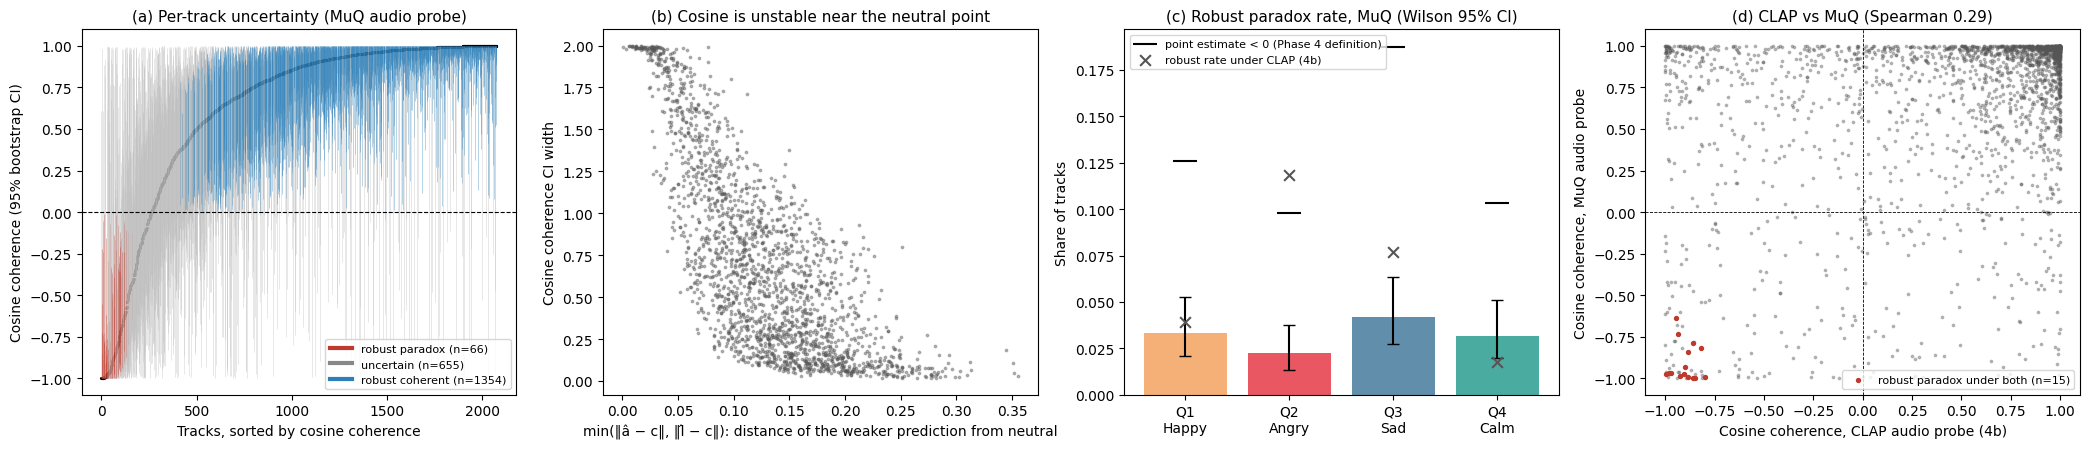

Saved: coherence_uncertainty_muq.png


In [12]:
coh.drop(columns=['genres']).to_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet'), index=False)
print('Saved: coherence_muq.parquet, coherence_probe_metrics_muq.csv, coherence_quadrant_summary_muq.csv, '
      'coherence_quadrant_tests_muq.csv, coherence_genre_tests_muq.csv, coherence_paradox_both_encoders.csv')

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
# (a) point estimate with 95% CI, sorted
ax = axes[0]
s = coh.sort_values('coh_cos').reset_index(drop=True)
colors = s.status_cos.map({'robust paradox': '#c0392b', 'uncertain': '#bbbbbb', 'robust coherent': '#2c7fb8'})
ax.vlines(s.index, s.coh_cos_lo, s.coh_cos_hi, colors=colors, lw=0.4, alpha=0.6)
ax.scatter(s.index, s.coh_cos, s=1.5, c='black')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Tracks, sorted by cosine coherence'); ax.set_ylabel('Cosine coherence (95% bootstrap CI)')
counts_st = coh.status_cos.value_counts()
ax.set_title('(a) Per-track uncertainty (MuQ audio probe)', fontsize=11)
for lbl, c in [('robust paradox', '#c0392b'), ('uncertain', '#888888'), ('robust coherent', '#2c7fb8')]:
    ax.plot([], [], color=c, lw=3, label=f'{lbl} (n={counts_st.get(lbl, 0)})')
ax.legend(fontsize=8, loc='lower right')
# (b) CI width vs distance from centre
ax = axes[1]
ax.scatter(coh.min_dev_from_center, coh.coh_cos_ci_width, s=3, alpha=0.4, color='#555555')
ax.set_xlabel('min(‖â − c‖, ‖l̂ − c‖): distance of the weaker prediction from neutral')
ax.set_ylabel('Cosine coherence CI width')
ax.set_title('(b) Cosine is unstable near the neutral point', fontsize=11)
# (c) robust paradox rate by quadrant
ax = axes[2]
x = np.arange(4)
ax.bar(x, qtab.robust_paradox_rate, color=[QCOL[q] for q in QUADS], alpha=0.85,
       yerr=[qtab.robust_paradox_rate - qtab.robust_ci_lo, qtab.robust_ci_hi - qtab.robust_paradox_rate], capsize=4)
ax.scatter(x, qtab.point_paradox_rate, marker='_', s=300, color='black', label='point estimate < 0 (Phase 4 definition)')
ax.set_xticks(x); ax.set_xticklabels([f'{q}\n{QLAB[q]}' for q in QUADS])
ax.set_ylabel('Share of tracks'); ax.set_title('(c) Robust paradox rate, MuQ (Wilson 95% CI)', fontsize=11)
ax.scatter(x, clap_q.robust_paradox_rate, marker='x', s=60, color='#555555', zorder=3, label='robust rate under CLAP (4b)')
ax.legend(fontsize=8)
# (d) CLAP vs MuQ cosine coherence
ax = axes[3]
ax.scatter(c2.coh_cos_clap, c2.coh_cos, s=3, alpha=0.35, color='#555555')
ax.scatter(c2.loc[both, 'coh_cos_clap'], c2.loc[both, 'coh_cos'], s=8, color='#c0392b', label=f'robust paradox under both (n={int(both.sum())})')
ax.axhline(0, color='black', lw=0.6, ls='--'); ax.axvline(0, color='black', lw=0.6, ls='--')
ax.set_xlabel('Cosine coherence, CLAP audio probe (4b)'); ax.set_ylabel('Cosine coherence, MuQ audio probe')
ax.set_title(f'(d) CLAP vs MuQ (Spearman {spearmanr(c2.coh_cos_clap, c2.coh_cos)[0]:.2f})', fontsize=11)
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_uncertainty_muq.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: coherence_uncertainty_muq.png')

## 9. Sensitivity: emotion-tuned lyrics probe
Is the MuQ paradox set specific to the SBERT lyrics probe? The lyrics probe is swapped for the emotion-tuned
DistilRoBERTa embedding (`text_emoroberta_emb.npy`, Phase 3b; best text representation for quadrant accuracy in 5e).
The audio probe (MuQ L7), folds and bootstrap resamples are **identical** to section 2: the bootstrap index draws are
replayed from the same seed, so `boot_a` is reused and only the lyrics probe is refit.

In [13]:
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == sids
X_r = np.load(os.path.join(ENC_DIR, 'text_emoroberta_emb.npy')).astype(np.float64)

rng_r = np.random.default_rng(SEED)                     # replays section 2's bootstrap draws exactly
pred_r, boot_r = np.zeros((n, 2)), np.zeros((N_BOOT, n, 2))
for f, (itr, ite) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_a, quad)):
    pr = make_probe().fit(X_r[itr], Y[itr]); ar = pr[-1].alpha_
    pred_r[ite] = pr.predict(X_r[ite])
    for b in range(N_BOOT):
        ib = rng_r.choice(itr, size=len(itr), replace=True)
        boot_r[b, ite] = make_probe(ar).fit(X_r[ib], Y[ib]).predict(X_r[ite])
    print(f'fold {f}: ridge α lyrics(EmoRoBERTa)={ar:.0f}')
print(f'OOF R² EmoRoBERTa probe: arousal {r2_score(Y[:, 0], pred_r[:, 0]):.3f}  valence {r2_score(Y[:, 1], pred_r[:, 1]):.3f}  '
      f'(SBERT: {r2_score(Y[:, 0], pred_l[:, 0]):.3f} / {r2_score(Y[:, 1], pred_l[:, 1]):.3f})')

coh_r = cos_coh(pred_a, pred_r)
lo_r, hi_r = np.percentile(cos_coh(boot_a, boot_r), [2.5, 97.5], axis=0)
status_r = np.select([hi_r < 0, lo_r > 0], ['robust paradox', 'robust coherent'], 'uncertain')
print(f"\nSpearman(MuQ+SBERT coherence, MuQ+EmoRoBERTa coherence) = {spearmanr(coh.coh_cos, coh_r)[0]:.3f}")
print(pd.crosstab(coh.status_cos.values, status_r, margins=True, rownames=['MuQ+SBERT'], colnames=['MuQ+EmoRoBERTa']).to_string())
rp_s, rp_r = coh.status_cos.values == 'robust paradox', status_r == 'robust paradox'
both_ids = set(pd.read_csv(os.path.join(OUT_DIR, 'coherence_paradox_both_encoders.csv'))['song_id'])
in_both = np.isin(sids, list(both_ids))
print(f'\nRobust paradoxes: MuQ+SBERT {rp_s.sum()}, MuQ+EmoRoBERTa {rp_r.sum()}, both lyrics probes {(rp_s & rp_r).sum()}')
print(f'Of the {in_both.sum()} tracks robust under CLAP+SBERT and MuQ+SBERT: {(in_both & rp_r).sum()} also robust with '
      f'MuQ+EmoRoBERTa; statuses with EmoRoBERTa: {pd.Series(status_r[in_both]).value_counts().to_dict()}')
pd.DataFrame({'song_id': sids, 'coh_cos_emoroberta': coh_r, 'coh_cos_emoroberta_lo': lo_r, 'coh_cos_emoroberta_hi': hi_r,
              'status_cos_emoroberta': status_r}).to_parquet(os.path.join(OUT_DIR, 'coherence_muq_emoroberta.parquet'), index=False)
print('Saved: coherence_muq_emoroberta.parquet')

fold 0: ridge α lyrics(EmoRoBERTa)=1000


fold 1: ridge α lyrics(EmoRoBERTa)=1000


fold 2: ridge α lyrics(EmoRoBERTa)=1000


fold 3: ridge α lyrics(EmoRoBERTa)=1000


fold 4: ridge α lyrics(EmoRoBERTa)=1000
OOF R² EmoRoBERTa probe: arousal 0.322  valence 0.475  (SBERT: 0.334 / 0.518)

Spearman(MuQ+SBERT coherence, MuQ+EmoRoBERTa coherence) = 0.585
MuQ+EmoRoBERTa   robust coherent  robust paradox  uncertain   All
MuQ+SBERT                                                        
robust coherent             1136               6        212  1354
robust paradox                 4              33         29    66
uncertain                    169              49        437   655
All                         1309              88        678  2075

Robust paradoxes: MuQ+SBERT 66, MuQ+EmoRoBERTa 88, both lyrics probes 33
Of the 15 tracks robust under CLAP+SBERT and MuQ+SBERT: 9 also robust with MuQ+EmoRoBERTa; statuses with EmoRoBERTa: {'robust paradox': 9, 'uncertain': 5, 'robust coherent': 1}
Saved: coherence_muq_emoroberta.parquet


## 10. Confound check: is coherence just emotional intensity or boundary distance?
Section 5 found that coherent queries are retrieved better. Two confounds could produce that without any role for
audio–lyrics agreement:
* **intensity:** tracks far from the neutral point (0.5, 0.5) are strongly emotional, easy to retrieve, and may also
  get agreeing probes;
* **boundary distance:** quadrant precision is mechanically harder for tracks near a quadrant boundary, and the
  cosine coherence of such tracks may be low because a probe crosses the boundary.

Covariates (per query): annotated distance from neutral ‖y − c‖, annotated distance from the nearest quadrant
boundary min(|a − 0.5|, |v − 0.5|), and the predicted distance from neutral (mean of the two probe magnitudes).
Partial Spearman correlation = Pearson correlation of rank residuals after regressing out the ranked covariates.
Outcomes: quadrant P@10 and nDCG@10 (σ = 0.10; graded relevance is less tied to quadrant boundaries).

In [14]:
from scipy.stats import rankdata, t as t_dist

D_AV  = np.linalg.norm(Y[:, None] - Y[None], axis=-1)
DISC  = 1 / np.log2(np.arange(2, 12))
def ndcg_at_10(S, sigma=0.10):
    S = S.copy(); S[np.arange(len(rows_te)), rows_te] = -np.inf
    top = np.argpartition(-S, 10, 1)[:, :10]
    top = np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)
    d = np.take_along_axis(D_AV[rows_te], top, 1)
    Dq = D_AV[rows_te].copy(); Dq[np.arange(len(rows_te)), rows_te] = np.inf
    idcg = (np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * sigma**2)) * DISC).sum(1)
    return (np.exp(-d**2 / (2 * sigma**2)) * DISC).sum(1) / idcg

S_late = 0.6 * SA + 0.4 * SL
out = pd.DataFrame({'P10_audio_only': p_at_10(SA), 'P10_lyrics_only': p_at_10(SL), 'P10_late_0.6': p_at_10(S_late),
                    'nDCG10_audio_only': ndcg_at_10(SA), 'nDCG10_lyrics_only': ndcg_at_10(SL), 'nDCG10_late_0.6': ndcg_at_10(S_late)},
                   index=np.array(sids)[rows_te])
assert np.allclose(out['P10_late_0.6'].values, wide['late_0.6'].values)       # same queries/order as section 5
ct = coh.set_index('song_id').loc[out.index]
cov = pd.DataFrame({
    'label_dist_center':   np.linalg.norm(ct[['arousal', 'valence']].values - CENTER, axis=1),
    'label_dist_boundary': np.minimum(np.abs(ct.arousal - 0.5), np.abs(ct.valence - 0.5)).values,
    'pred_dist_center':    0.5 * (np.linalg.norm(ct[['pred_audio_arousal', 'pred_audio_valence']].values - CENTER, axis=1)
                                  + np.linalg.norm(ct[['pred_lyrics_arousal', 'pred_lyrics_valence']].values - CENTER, axis=1)),
}, index=out.index)
print('Spearman of coherence with each covariate (test queries):')
print({k: round(spearmanr(ct.coh_cos, v)[0], 3) for k, v in cov.items()})

def partial_spearman(x, y, Z):
    rx, ry = rankdata(x), rankdata(y)
    if Z.shape[1]:
        Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z.T])
        rx = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
        ry = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]; df = len(x) - 2 - Z.shape[1]
    return r, 2 * t_dist.sf(abs(r) * np.sqrt(df / (1 - r**2)), df)

sets = {'none': [], 'label intensity': ['label_dist_center'], 'boundary distance': ['label_dist_boundary'],
        'predicted intensity': ['pred_dist_center'], 'all three': list(cov.columns)}
rows = []
for outcome in out.columns:
    for sname, cols in sets.items():
        r, pv = partial_spearman(ct.coh_cos.values, out[outcome].values, cov[cols].values)
        rows.append({'outcome': outcome, 'controls': sname, 'partial_spearman': r, 'p': pv})
pc = pd.DataFrame(rows)
pc['p_holm'] = np.nan
for sname in sets:
    i = pc.controls == sname; pc.loc[i, 'p_holm'] = holm(pc.loc[i, 'p'].values)
tab = pc.pivot(index='outcome', columns='controls', values='partial_spearman')[list(sets)]
star = pc.pivot(index='outcome', columns='controls', values='p_holm')[list(sets)] < 0.05
print('\nPartial Spearman(coherence, per-query retrieval | controls); * = Holm p < 0.05 within each control set')
print(tab.round(3).astype(str).where(~star, tab.round(3).astype(str) + '*').to_string())

# Stratified view: coherence tercile effect within terciles of boundary distance
sv = out.join(ct[['coh_cos']]).join(cov)
sv['coh_tercile'] = pd.qcut(sv.coh_cos, 3, labels=['low coh', 'mid coh', 'high coh'])
sv['boundary_tercile'] = pd.qcut(sv.label_dist_boundary, 3, labels=['near boundary', 'middle', 'far from boundary'])
print('\nMean fused P@10 (late 0.6) by boundary-distance tercile (rows) and coherence tercile (cols):')
print(sv.pivot_table(index='boundary_tercile', columns='coh_tercile', values='P10_late_0.6', aggfunc='mean').round(3).to_string())
print('\nn per cell:')
print(sv.pivot_table(index='boundary_tercile', columns='coh_tercile', values='P10_late_0.6', aggfunc='size').to_string())
sv['intensity_tercile'] = pd.qcut(sv.label_dist_center, 3, labels=['low intensity', 'mid', 'high intensity'])
print('\nMean fused nDCG@10 by intensity tercile (rows) and coherence tercile (cols):')
print(sv.pivot_table(index='intensity_tercile', columns='coh_tercile', values='nDCG10_late_0.6', aggfunc='mean').round(3).to_string())
pc.to_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq.csv'), index=False)
print('Saved: coherence_confound_check_muq.csv')

Spearman of coherence with each covariate (test queries):
{'label_dist_center': -0.01, 'label_dist_boundary': -0.162, 'pred_dist_center': 0.306}

Partial Spearman(coherence, per-query retrieval | controls); * = Holm p < 0.05 within each control set
controls              none label intensity boundary distance predicted intensity all three
outcome                                                                                   
P10_audio_only       0.36*          0.364*            0.335*              0.288*     0.26*
P10_late_0.6        0.328*          0.335*            0.301*              0.256*    0.231*
P10_lyrics_only     0.389*          0.399*            0.369*              0.342*    0.336*
nDCG10_audio_only   0.361*          0.364*            0.342*               0.29*    0.272*
nDCG10_late_0.6     0.334*          0.341*            0.313*              0.265*    0.254*
nDCG10_lyrics_only  0.344*          0.353*            0.321*              0.297*    0.286*

Mean fused P@10 (late 

Saved: coherence_confound_check_muq.csv
